# Notebook 06 V2 — Đánh giá test và so sánh V1–V2

Notebook này chỉ đánh giá checkpoint V2 đã đóng băng trên đúng tập test 159 bài của V1.

- Không train, không tạo optimizer/scheduler và không thay đổi trọng số.
- Không sửa train, validation, test, nhãn hoặc checkpoint V1/V2.
- Mặc định test bị khóa. Chỉ đổi `EVALUATE_TEST = True` sau khi người dùng xác nhận chạy.
- Nếu đã có bất kỳ output test V2 nào, notebook dừng trước khi mã hóa hoặc chạy model.
- Bảng cuối chỉ mô tả V1–V2; không dùng test để chọn lại cấu hình hay retrain.
- Đây là so sánh hậu nghiệm vì test V1 đã tồn tại trước V2; không gọi là test mù cho toàn dự án.


## 1. Khóa test

Cell dưới đây cố ý dừng `Run all` ở trạng thái mặc định. Việc tạo notebook không đồng nghĩa cho phép mở test.


In [ ]:
RUN_NAME = 'review38_incremental_v2'
PARENT_RUN_NAME = '20261024_153932_380173'
EVALUATE_TEST = False

if EVALUATE_TEST is not True:
    raise RuntimeError(
        'Test V2 đang khóa. Chỉ đổi EVALUATE_TEST = True sau khi xác nhận chạy notebook 06 V2.'
    )


## 2. Thiết lập môi trường

Trên Colab, dùng GPU T4, gói `news_processing_v2_colab.zip` và cùng thư mục Drive của V1/V2.


In [8]:
import hashlib
import io
import json
import os
import shutil
import subprocess
import sys
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path


In [9]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import torch
    from packaging.version import Version
    if not torch.cuda.is_available():
        raise RuntimeError('Chưa có CUDA. Chọn GPU T4 trong Colab rồi kết nối lại.')
    if Version(torch.__version__.split('+')[0]) < Version('2.6'):
        raise RuntimeError('Cần runtime Colab có PyTorch >= 2.6.')
    print('GPU được cấp:', torch.cuda.get_device_name(0))
    print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))


GPU được cấp: Tesla T4
VRAM (GB): 14.6


In [10]:
if IN_COLAB:
    colab_packages = [
        'transformers==4.57.1', 'py-vncorenlp==0.1.4',
        'pandas>=2.2,<3', 'scikit-learn>=1.7,<1.8',
        'matplotlib>=3.10,<4', 'tqdm>=4.67,<5',
    ]
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet', *colab_packages,
    ])
    if shutil.which('java') is None:
        subprocess.check_call(['apt-get', '-qq', 'update'])
        subprocess.check_call(['apt-get', '-qq', 'install', '-y', 'openjdk-17-jre-headless'])


In [11]:
COLAB_OUTPUT_DIR = None
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    COLAB_OUTPUT_DIR = Path('/content/drive/MyDrive/stock_news_anomaly_project')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
COLAB_PROJECT_DIR = Path('/content/news_processing') if IN_COLAB else None
if IN_COLAB:
    project_archive = COLAB_OUTPUT_DIR / 'news_processing_v2_colab.zip'
    if not project_archive.is_file():
        project_archive = Path('/content/news_processing_v2_colab.zip')
    if not project_archive.is_file():
        raise FileNotFoundError('Thiếu news_processing_v2_colab.zip trong Drive hoặc /content.')
    with zipfile.ZipFile(project_archive) as archive:
        for member in archive.infolist():
            target_path = (Path('/content') / member.filename).resolve()
            if not target_path.is_relative_to(COLAB_PROJECT_DIR.resolve()):
                raise ValueError('Gói ZIP phải chỉ chứa thư mục news_processing.')
        archive.extractall('/content')
    print('Đã cập nhật dữ liệu/code từ:', project_archive)


Đã cập nhật dữ liệu/code từ: /content/drive/MyDrive/stock_news_anomaly_project/news_processing_v2_colab.zip


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch import nn
from torch.utils.data import DataLoader, SequentialSampler
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer


In [14]:
CURRENT_DIR = Path.cwd().resolve()
PROJECT_CANDIDATES = ([COLAB_PROJECT_DIR] if IN_COLAB else []) + [
    CURRENT_DIR / 'news_processing', CURRENT_DIR, *CURRENT_DIR.parents,
]
PROJECT_DIR = next(
    (path for path in PROJECT_CANDIDATES
     if path is not None and (path / 'src').is_dir() and (path / 'data').is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Không tìm thấy news_processing chứa src/ và data/.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))


In [15]:
from src.news_type_training import (
    evaluate_classifier,
    restore_saved_checkpoint,
    seed_everything,
    validate_saved_segmenter,
    verify_test_evaluation_manifest,
)
from src.phobert_cnn import EncodedNewsDataset, PhoBertCNN, encode_news_texts


## 3. Khóa checkpoint, dữ liệu và đường dẫn output

V2 dùng `train_v2.csv` trong provenance. Notebook không dùng helper test V1 vốn khóa cứng `train.csv`.


In [16]:
OUTPUT_ROOT = COLAB_OUTPUT_DIR if IN_COLAB else PROJECT_DIR
MODEL_ROOT = OUTPUT_ROOT / 'models/news_type_phobert_cnn'
REPORT_ROOT = OUTPUT_ROOT / 'reports/news_type'

MODEL_RUN_DIR = MODEL_ROOT / 'v2/runs' / RUN_NAME
RUN_REPORT_DIR = REPORT_ROOT / 'v2/runs' / RUN_NAME
V1_MODEL_RUN_DIR = MODEL_ROOT / 'runs' / PARENT_RUN_NAME
V1_TEST_REPORT_DIR = REPORT_ROOT / 'evaluations/validation_review_20261025_v2'
V1_TEST_MANIFEST_PATH = V1_TEST_REPORT_DIR / 'test_evaluation_config.json'

SPLIT_DIR = PROJECT_DIR / 'data/splits/news_type'
V1_TRAIN_PATH = SPLIT_DIR / 'train.csv'
REVIEW38_RESOLUTION_PATH = (
    PROJECT_DIR / 'data/annotation/news_type/review38/review38_resolution.csv'
)
INPUT_PATHS = {
    'data/splits/news_type/train_v2.csv': SPLIT_DIR / 'train_v2.csv',
    'data/splits/news_type/validation.csv': SPLIT_DIR / 'validation.csv',
    'data/splits/news_type/test.csv': SPLIT_DIR / 'test.csv',
    'models/news_type_phobert_cnn/label_mapping.json': (
        PROJECT_DIR / 'models/news_type_phobert_cnn/label_mapping.json'
    ),
}
VALIDATION_REVISION_PATH = PROJECT_DIR / 'data/annotation/news_type/validation_revision.json'
VNCORENLP_DIR = PROJECT_DIR / 'models/vncorenlp'

TEST_OUTPUT_PATHS = {
    'test_metrics.json': RUN_REPORT_DIR / 'test_metrics.json',
    'test_predictions.csv': RUN_REPORT_DIR / 'test_predictions.csv',
    'test_classification_report.csv': RUN_REPORT_DIR / 'test_classification_report.csv',
    'test_confusion_matrix.png': RUN_REPORT_DIR / 'test_confusion_matrix.png',
    'test_class_f1.png': RUN_REPORT_DIR / 'test_class_f1.png',
    'v1_v2_comparison.csv': RUN_REPORT_DIR / 'v1_v2_comparison.csv',
    'test_evaluation_config.json': RUN_REPORT_DIR / 'test_evaluation_config.json',
}

EXPECTED_TEST_ROWS = 159
EXPECTED_TEST_SHA256 = '1e40f86ac0e85772ccbea65f0ee815eb78277ec91e0834de91d0c66aa4270bf0'
EXPECTED_REVIEW38_RESOLUTION_SHA256 = '67329145acb296f65c1caa9be5bc6bf9c0f5da9f607d3fe22a68131b17e49616'
EXPECTED_VALIDATION_REVISION_SHA256 = 'a70c645f018d739467ce15d947d27b276454022837f7c766f0393096ff6a2036'


In [17]:
required_paths = [
    *INPUT_PATHS.values(), V1_TRAIN_PATH, REVIEW38_RESOLUTION_PATH,
    VALIDATION_REVISION_PATH,
    MODEL_RUN_DIR / 'best_model.pt', MODEL_RUN_DIR / 'run_config.json',
    V1_MODEL_RUN_DIR / 'best_model.pt', V1_MODEL_RUN_DIR / 'run_config.json',
    RUN_REPORT_DIR / 'selection_decision.json',
    RUN_REPORT_DIR / 'validation_metrics.json',
    V1_TEST_MANIFEST_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError('Thiếu đầu vào bắt buộc: ' + ', '.join(missing_paths))
if not (MODEL_RUN_DIR / 'tokenizer').is_dir() or not (MODEL_RUN_DIR / 'backbone').is_dir():
    raise FileNotFoundError('Run V2 thiếu tokenizer hoặc backbone config.')
if not (V1_MODEL_RUN_DIR / 'tokenizer').is_dir() or not (V1_MODEL_RUN_DIR / 'backbone').is_dir():
    raise FileNotFoundError('Run V1 thiếu tokenizer hoặc backbone config.')
if not RUN_REPORT_DIR.is_dir():
    raise FileNotFoundError('Thiếu thư mục báo cáo V2 từ notebook 05.')

report_root_resolved = RUN_REPORT_DIR.resolve()
if any(path.resolve().parent != report_root_resolved for path in TEST_OUTPUT_PATHS.values()):
    raise ValueError('Output test phải nằm trực tiếp trong thư mục báo cáo V2.')
existing_outputs = [str(path) for path in TEST_OUTPUT_PATHS.values() if path.exists()]
if existing_outputs:
    raise FileExistsError(
        'Test V2 đã có output; dừng trước khi mã hóa/chạy model: ' + ', '.join(existing_outputs)
    )

run_config_path = MODEL_RUN_DIR / 'run_config.json'
run_config = json.loads(run_config_path.read_text(encoding='utf-8-sig'))
label_mapping = json.loads(
    INPUT_PATHS['models/news_type_phobert_cnn/label_mapping.json'].read_text(
        encoding='utf-8-sig'
    )
)
selection_manifest = json.loads(
    (RUN_REPORT_DIR / 'selection_decision.json').read_text(encoding='utf-8-sig')
)
saved_validation_metrics = json.loads(
    (RUN_REPORT_DIR / 'validation_metrics.json').read_text(encoding='utf-8-sig')
)
v1_test_manifest_preview = json.loads(
    V1_TEST_MANIFEST_PATH.read_text(encoding='utf-8-sig')
)

expected_config = {
    'run_name': RUN_NAME,
    'run_version': 'news_type_v2_review38_incremental',
    'parent_run': PARENT_RUN_NAME,
    'initialization': 'warm_start_model_weights_new_optimizer',
    'model_name': 'vinai/phobert-base-v2',
    'train_rows': 766,
    'review38_added_rows': 26,
    'test_evaluated': False,
}
config_mismatches = {
    name: {'expected': expected, 'observed': run_config.get(name)}
    for name, expected in expected_config.items() if run_config.get(name) != expected
}
if config_mismatches:
    raise ValueError(f'Run V2 không đúng cấu hình đã khóa: {config_mismatches}')

observed_input_sha256 = {
    name: hashlib.sha256(path.read_bytes()).hexdigest()
    for name, path in INPUT_PATHS.items()
}
if observed_input_sha256 != run_config.get('input_sha256'):
    raise ValueError('Dữ liệu hiện tại không khớp provenance của checkpoint V2.')
if observed_input_sha256['data/splits/news_type/test.csv'] != EXPECTED_TEST_SHA256:
    raise ValueError('Sai tập test đã khóa.')
if run_config.get('label_mapping') != label_mapping:
    raise ValueError('Label mapping hiện tại khác mapping của checkpoint V2.')
if label_mapping.get('label_policy_version') != 'company_awards_listing_v2':
    raise ValueError('Sai phiên bản chính sách nhãn.')

checkpoint_sha256 = hashlib.sha256((MODEL_RUN_DIR / 'best_model.pt').read_bytes()).hexdigest()
if checkpoint_sha256 != run_config.get('candidate_checkpoint_sha256'):
    raise ValueError('Checkpoint V2 khác checkpoint đã ghi trong run_config.')
if selection_manifest.get('candidate_run') != RUN_NAME:
    raise ValueError('Quyết định validation không thuộc candidate V2 hiện tại.')
if saved_validation_metrics != run_config.get('candidate_validation_metrics'):
    raise ValueError('Chỉ số validation V2 không khớp run_config.')

review38_resolution_sha256 = hashlib.sha256(
    REVIEW38_RESOLUTION_PATH.read_bytes()
).hexdigest()
if (review38_resolution_sha256 != EXPECTED_REVIEW38_RESOLUTION_SHA256
        or review38_resolution_sha256 != run_config.get('review38_resolution_sha256')):
    raise ValueError('review38 resolution does not match the data used to train V2.')
validation_revision_sha256 = hashlib.sha256(
    VALIDATION_REVISION_PATH.read_bytes()
).hexdigest()
if validation_revision_sha256 != EXPECTED_VALIDATION_REVISION_SHA256:
    raise ValueError('Validation revision differs from the locked revision.')

test_data = pd.read_csv(
    INPUT_PATHS['data/splits/news_type/test.csv'], dtype=str, keep_default_na=False,
)
label2id = label_mapping['label2id']
ordered_labels = sorted(label2id, key=label2id.get)
NUM_CLASSES = len(ordered_labels)
if sorted(label2id.values()) != list(range(NUM_CLASSES)):
    raise ValueError('label_id values must be contiguous from zero.')
raw_class_weights = run_config.get('class_weights_by_id')
numeric_class_weights = np.asarray(raw_class_weights, dtype=float)
if (not isinstance(raw_class_weights, list) or numeric_class_weights.shape != (NUM_CLASSES,)
        or not np.isfinite(numeric_class_weights).all()
        or (numeric_class_weights <= 0).any()):
    raise ValueError('V2 class weights must be complete, finite and positive.')
if (not isinstance(run_config.get('batch_size'), int) or run_config['batch_size'] <= 0
        or not isinstance(run_config.get('max_length'), int) or run_config['max_length'] < 3
        or not isinstance(run_config.get('head_ratio'), (int, float))
        or not np.isfinite(run_config['head_ratio'])
        or not 0 <= run_config['head_ratio'] <= 1):
    raise ValueError('V2 batch size or sequence truncation settings are invalid.')
required_test_columns = {
    'news_id', 'source', 'input_text', 'news_type', 'label_id', 'split',
}
if not required_test_columns.issubset(test_data.columns):
    raise ValueError('Test thiếu trường bắt buộc.')
test_data['label_id'] = pd.to_numeric(test_data['label_id'], errors='raise').astype(int)
mapped_test_ids = test_data['news_type'].map(label2id)
if mapped_test_ids.isna().any() or not test_data['label_id'].eq(mapped_test_ids).all():
    raise ValueError('Nhãn test không khớp label mapping.')
if (len(test_data) != EXPECTED_TEST_ROWS or test_data['news_id'].duplicated().any()
        or not test_data['split'].eq('test').all()):
    raise ValueError('Số dòng, ID hoặc tên split của test không đúng.')

v1_input_sha256 = {
    'models/news_type_phobert_cnn/label_mapping.json': observed_input_sha256[
        'models/news_type_phobert_cnn/label_mapping.json'
    ],
    'data/splits/news_type/train.csv': hashlib.sha256(V1_TRAIN_PATH.read_bytes()).hexdigest(),
    'data/splits/news_type/validation.csv': observed_input_sha256[
        'data/splits/news_type/validation.csv'
    ],
    'data/splits/news_type/test.csv': observed_input_sha256[
        'data/splits/news_type/test.csv'
    ],
}
preview_test_hash = v1_test_manifest_preview.get('input_sha256', {}).get(
    'data/splits/news_type/test.csv'
)
if (v1_test_manifest_preview.get('test_evaluated') is not True
        or v1_test_manifest_preview.get('source_run') != PARENT_RUN_NAME
        or v1_test_manifest_preview.get('test_count') != EXPECTED_TEST_ROWS
        or preview_test_hash != EXPECTED_TEST_SHA256):
    raise ValueError('Hồ sơ test V1 không khai báo cùng tập test 159 bài.')
if v1_test_manifest_preview.get('label_mapping', {}).get('label2id') != label2id:
    raise ValueError('V1 và V2 không dùng cùng ánh xạ nhãn.')

print('Preflight đạt: checkpoint V2 và cùng tập test V1 đã được khóa.')
print('Quyết định ở validation (chỉ ghi nhận):', selection_manifest.get('decision'))


Preflight đạt: checkpoint V2 và cùng tập test V1 đã được khóa.
Quyết định ở validation (chỉ ghi nhận): KEEP_V1_PARENT


## 4. Tách từ và mã hóa test

Từ đây bắt đầu lượt đánh giá test V2 đã lên kế hoạch. Không chạy lại nếu đã xuất bất kỳ artifact test V2 nào.


In [18]:
seed_everything(int(run_config['seed']))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if IN_COLAB and DEVICE.type != 'cuda':
    raise RuntimeError('Colab phải dùng GPU cho đánh giá V2.')

java_executable_name = 'java.exe' if os.name == 'nt' else 'java'
java_home_candidates = [
    Path(os.environ[name]) for name in ('JAVA_HOME', 'JDK_HOME', 'JRE_HOME')
    if os.environ.get(name)
]
java_home_candidates.extend(sorted((PROJECT_DIR / 'models/java').glob('*')))
java_on_path = shutil.which('java')
if java_on_path:
    java_home_candidates.append(Path(java_on_path).resolve().parent.parent)
java_home = next(
    (path.resolve() for path in java_home_candidates
     if (path / 'bin' / java_executable_name).is_file()),
    None,
)
if java_home is not None:
    os.environ['JAVA_HOME'] = str(java_home)
    java_bin_path = str(java_home / 'bin')
    if java_bin_path not in os.environ.get('PATH', '').split(os.pathsep):
        os.environ['PATH'] = java_bin_path + os.pathsep + os.environ.get('PATH', '')
if shutil.which('java') is None:
    raise RuntimeError('Không tìm thấy Java cho VnCoreNLP.')
print('Thiết bị:', DEVICE, '| Java:', shutil.which('java'))


Thiết bị: cuda | Java: /usr/lib/jvm/java-21-openjdk-amd64/bin/java


In [19]:
vncorenlp_resources = (
    'VnCoreNLP-1.2.jar',
    'models/wordsegmenter/vi-vocab',
    'models/wordsegmenter/wordsegmenter.rdr',
)
missing_segmenter = [
    relative_path for relative_path in vncorenlp_resources
    if not (VNCORENLP_DIR / relative_path).is_file()
]
if missing_segmenter:
    raise FileNotFoundError('Thiếu tài nguyên VnCoreNLP: ' + ', '.join(missing_segmenter))
segmenter_sha256 = {
    relative_path: hashlib.sha256((VNCORENLP_DIR / relative_path).read_bytes()).hexdigest()
    for relative_path in vncorenlp_resources
}
validate_saved_segmenter(run_config, segmenter_sha256)

v1_run_config = json.loads(
    (V1_MODEL_RUN_DIR / 'run_config.json').read_text(encoding='utf-8-sig')
)
v1_test_manifest = verify_test_evaluation_manifest(
    V1_MODEL_RUN_DIR,
    V1_TEST_REPORT_DIR,
    input_sha256=v1_input_sha256,
    label_mapping=label_mapping,
    validation_revision_sha256=validation_revision_sha256,
    segmenter_sha256=segmenter_sha256,
    max_length=int(v1_run_config['max_length']),
    head_ratio=float(v1_run_config['head_ratio']),
    test_data=test_data,
)
print('Đã xác minh lại metrics V1 từ checkpoint và toàn bộ prediction test đã lưu.')


Đã xác minh lại metrics V1 từ checkpoint và toàn bộ prediction test đã lưu.


In [20]:
import py_vncorenlp

working_directory = Path.cwd()
try:
    segmenter = py_vncorenlp.VnCoreNLP(annotators=['wseg'], save_dir=str(VNCORENLP_DIR))
finally:
    os.chdir(working_directory)

tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_RUN_DIR / 'tokenizer'), use_fast=False, local_files_only=True,
)
MAX_LENGTH = int(run_config['max_length'])
HEAD_RATIO = float(run_config['head_ratio'])
test_encodings = encode_news_texts(
    tqdm(test_data['input_text'], desc='Mã hóa test V2'), segmenter, tokenizer,
    max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
)
if len(test_encodings) != EXPECTED_TEST_ROWS:
    raise RuntimeError('Không mã hóa đủ toàn bộ test.')
truncated_count = sum(
    item['original_token_count'] > item['retained_token_count'] for item in test_encodings
)
print('Đã mã hóa:', len(test_encodings), '| Bài bị cắt token:', truncated_count)


Mã hóa test V2:   0%|          | 0/159 [00:00<?, ?it/s]

Đã mã hóa: 159 | Bài bị cắt token: 149


In [21]:
test_dataset = EncodedNewsDataset(test_encodings, test_data['label_id'].tolist())
test_loader = DataLoader(
    test_dataset, batch_size=int(run_config['batch_size']), shuffle=False,
    num_workers=0, pin_memory=DEVICE.type == 'cuda', drop_last=False,
)
if (not isinstance(test_loader.sampler, SequentialSampler)
        or test_loader.drop_last or len(test_loader.dataset) != EXPECTED_TEST_ROWS):
    raise ValueError('Test loader phải tuần tự và giữ đủ 159 bài.')
dataset_labels = [int(record['labels']) for record in test_dataset.records]
if dataset_labels != test_data['label_id'].tolist():
    raise ValueError('Thứ tự nhãn trong test dataset đã thay đổi.')


## 5. Nạp checkpoint đóng băng và đánh giá

Model được đặt ở `eval`, khóa gradient và chỉ chạy forward trên test.


In [22]:
backbone_config = AutoConfig.from_pretrained(
    str(MODEL_RUN_DIR / 'backbone'), local_files_only=True,
)
backbone = AutoModel.from_config(backbone_config)
model = PhoBertCNN(
    backbone=backbone, num_classes=NUM_CLASSES,
    kernel_sizes=run_config['kernel_sizes'], num_filters=run_config['num_filters'],
    global_projection_size=run_config['global_projection_size'],
    dropout=run_config['dropout'],
).to(DEVICE)
checkpoint_metadata = restore_saved_checkpoint(
    model, MODEL_RUN_DIR, run_config, DEVICE,
)
for parameter in model.parameters():
    parameter.requires_grad_(False)
model.eval()
if checkpoint_metadata['epoch'] != run_config['best_epoch']:
    raise ValueError('Epoch checkpoint không khớp run_config.')
print('Đã nạp checkpoint V2 epoch:', checkpoint_metadata['epoch'])


Đã nạp checkpoint V2 epoch: 1


In [23]:
class_weights = torch.as_tensor(
    run_config['class_weights_by_id'], dtype=torch.float32,
)
if (class_weights.shape != (NUM_CLASSES,) or not torch.isfinite(class_weights).all()
        or bool((class_weights <= 0).any())):
    raise ValueError('Class weight V2 phải đủ, hữu hạn và dương.')
class_weights = class_weights.to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
metric_names = ('loss', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy')

test_results = evaluate_classifier(
    model, test_loader, DEVICE, NUM_CLASSES, criterion=criterion,
)
test_metrics = {name: float(test_results[name]) for name in metric_names}
test_class_report = pd.DataFrame(classification_report(
    test_results['labels'], test_results['predictions'],
    labels=list(range(NUM_CLASSES)), target_names=ordered_labels,
    output_dict=True, zero_division=0,
)).T
display(pd.DataFrame([test_metrics], index=['V2 test']).round(4))
display(test_class_report.round(4))


,loss,accuracy,macro_f1,weighted_f1,balanced_accuracy
V2 test,0.7532,0.8239,0.8045,0.822,0.8352


,precision,recall,f1-score,support
governance_capital,0.8400,0.9130,0.8750,23.0000
financial_results,0.8077,0.7778,0.7925,27.0000
business_operations,0.8723,0.9111,0.8913,45.0000
legal_compliance,0.7000,1.0000,0.8235,7.0000
industry,0.7500,0.8333,0.7895,18.0000
stock_market,0.9500,0.6333,0.7600,30.0000
mention_only,0.6364,0.7778,0.7000,9.0000
accuracy,0.8239,0.8239,0.8239,0.8239
macro avg,0.7938,0.8352,0.8045,159.0000
weighted avg,0.8365,0.8239,0.8220,159.0000


In [24]:
test_predictions = test_data[['news_id', 'source', 'news_type']].copy()
test_predictions['predicted_news_type'] = [
    ordered_labels[int(label_id)] for label_id in test_results['predictions']
]
test_predictions['predicted_probability'] = test_results['probabilities'].max(axis=1)
test_predictions['is_correct'] = test_predictions['news_type'].eq(
    test_predictions['predicted_news_type']
)
if len(test_predictions) != EXPECTED_TEST_ROWS:
    raise RuntimeError('Kết quả dự đoán không đủ toàn bộ test.')

truth = test_data['label_id'].to_numpy(dtype=int)
guessed = test_predictions['predicted_news_type'].map(label2id).to_numpy(dtype=int)
classes = list(range(NUM_CLASSES))
recomputed_metrics = {
    'accuracy': accuracy_score(truth, guessed),
    'macro_f1': f1_score(truth, guessed, labels=classes, average='macro', zero_division=0),
    'weighted_f1': f1_score(
        truth, guessed, labels=classes, average='weighted', zero_division=0,
    ),
    'balanced_accuracy': balanced_accuracy_score(truth, guessed),
}
if any(
    abs(float(test_metrics[name]) - float(value)) > 1e-10
    for name, value in recomputed_metrics.items()
):
    raise RuntimeError('Metric test không khớp bảng dự đoán đầy đủ.')


## 6. Biểu đồ và bảng so sánh mô tả

Không sinh quyết định chọn model từ test. Loss không được đưa vào bảng V1–V2 vì hai run có thể dùng class weight khác nhau.


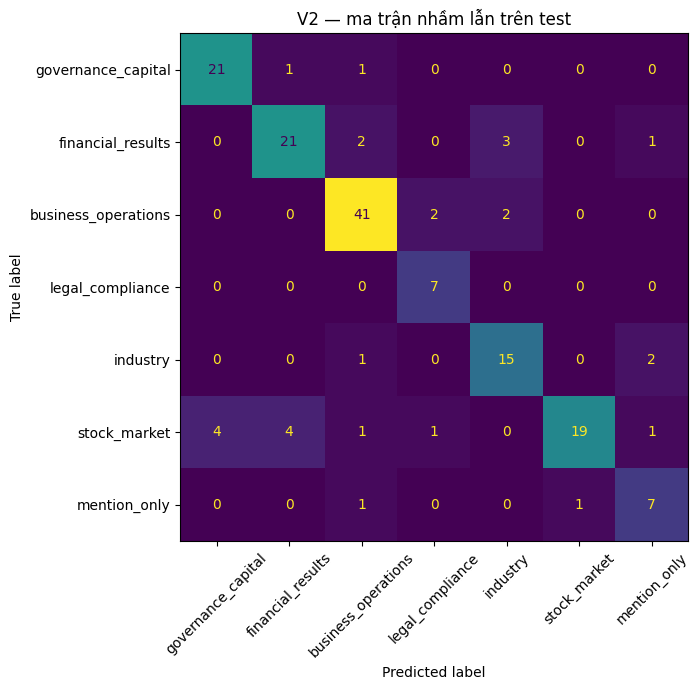

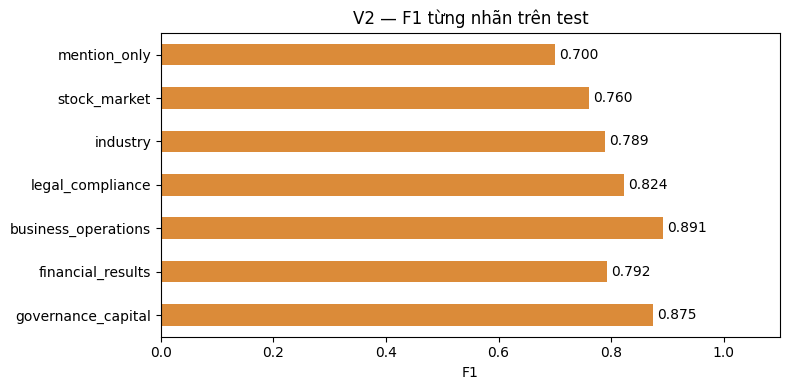

In [25]:
test_confusion = confusion_matrix(
    test_results['labels'], test_results['predictions'], labels=list(range(NUM_CLASSES)),
)
confusion_figure, confusion_axis = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(test_confusion, display_labels=ordered_labels).plot(
    ax=confusion_axis, xticks_rotation=45, colorbar=False,
)
confusion_axis.set_title('V2 — ma trận nhầm lẫn trên test')
confusion_figure.tight_layout()
confusion_buffer = io.BytesIO()
confusion_figure.savefig(confusion_buffer, format='png', dpi=160)
plt.show()

class_f1 = test_class_report.loc[ordered_labels, 'f1-score']
class_axis = class_f1.plot.barh(figsize=(8, 4), color='#DB8B39')
class_axis.bar_label(class_axis.containers[0], fmt='%.3f', padding=3)
class_axis.set(title='V2 — F1 từng nhãn trên test', xlabel='F1', ylabel='', xlim=(0, 1.1))
class_axis.figure.tight_layout()
class_f1_buffer = io.BytesIO()
class_axis.figure.savefig(class_f1_buffer, format='png', dpi=160)
plt.show()


In [26]:
comparison_metric_names = ('accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy')
metric_sources = {
    ('V1 baseline', 'validation'): run_config['source_validation_metrics'],
    ('V1 baseline', 'test'): v1_test_manifest['metrics'],
    ('V2 candidate', 'validation'): run_config['candidate_validation_metrics'],
    ('V2 candidate', 'test'): test_metrics,
}
comparison_rows = []
for (model_name, split_name), metrics in metric_sources.items():
    if any(name not in metrics for name in comparison_metric_names):
        raise ValueError(f'Thiếu metric để so sánh: {model_name} / {split_name}')
    comparison_rows.append({
        'model': model_name,
        'split': split_name,
        **{name: float(metrics[name]) for name in comparison_metric_names},
    })
v1_v2_comparison = pd.DataFrame(comparison_rows)
display(v1_v2_comparison.round(4))
print('Bảng này chỉ mô tả kết quả; không tự chọn V1 hay V2 từ test.')


,model,split,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,V1 baseline,validation,0.9308,0.9107,0.9297,0.9062
1,V1 baseline,test,0.8239,0.8038,0.8208,0.8169
2,V2 candidate,validation,0.8994,0.8800,0.9016,0.8829
3,V2 candidate,test,0.8239,0.8045,0.8220,0.8352


Bảng này chỉ mô tả kết quả; không tự chọn V1 hay V2 từ test.


## 7. Lưu kết quả test V2 và provenance

Tất cả file được tạo mới bằng chế độ không ghi đè. Nếu ghi lỗi giữa chừng, chỉ các file vừa tạo trong cell này được thu hồi.


In [27]:
test_metrics_bytes = (
    json.dumps(test_metrics, ensure_ascii=False, indent=2) + '\n'
).encode('utf-8')
test_predictions_bytes = test_predictions.to_csv(
    index=False, lineterminator='\n',
).encode('utf-8-sig')
test_class_report_bytes = test_class_report.to_csv(
    lineterminator='\n',
).encode('utf-8-sig')
comparison_bytes = v1_v2_comparison.to_csv(
    index=False, lineterminator='\n',
).encode('utf-8-sig')

artifact_payloads = {
    'test_metrics.json': test_metrics_bytes,
    'test_predictions.csv': test_predictions_bytes,
    'test_classification_report.csv': test_class_report_bytes,
    'test_confusion_matrix.png': confusion_buffer.getvalue(),
    'test_class_f1.png': class_f1_buffer.getvalue(),
    'v1_v2_comparison.csv': comparison_bytes,
}
artifact_sha256 = {
    name: hashlib.sha256(payload).hexdigest()
    for name, payload in artifact_payloads.items()
}
model_assets_sha256 = {
    path.relative_to(MODEL_RUN_DIR).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
    for folder_name in ('tokenizer', 'backbone')
    for path in sorted((MODEL_RUN_DIR / folder_name).rglob('*')) if path.is_file()
}
if not model_assets_sha256:
    raise FileNotFoundError('Không tìm thấy tokenizer/backbone đã lưu của V2.')

test_evaluation_manifest = {
    'schema_version': 1,
    'evaluation_kind': 'frozen_v1_v2_comparison',
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'evaluated_split': 'test',
    'test_evaluated': True,
    'test_context': 'post_hoc_shared_test; V1 test artifacts existed before V2',
    'test_used_for_model_selection': False,
    'model_retrained': False,
    'source_run': RUN_NAME,
    'parent_run': PARENT_RUN_NAME,
    'validation_stage_decision': selection_manifest.get('decision'),
    'checkpoint_epoch': int(checkpoint_metadata['epoch']),
    'checkpoint_sha256': checkpoint_sha256,
    'run_config_sha256': hashlib.sha256(run_config_path.read_bytes()).hexdigest(),
    'model_assets_sha256': model_assets_sha256,
    'input_sha256': observed_input_sha256,
    'label_mapping': label_mapping,
    'validation_revision_sha256': hashlib.sha256(
        VALIDATION_REVISION_PATH.read_bytes()
    ).hexdigest(),
    'segmenter_sha256': segmenter_sha256,
    'max_length': MAX_LENGTH,
    'head_ratio': HEAD_RATIO,
    'test_count': len(test_data),
    'metrics': test_metrics,
    'artifact_sha256': artifact_sha256,
    'v1_test_manifest_sha256': hashlib.sha256(
        V1_TEST_MANIFEST_PATH.read_bytes()
    ).hexdigest(),
    'v1_test_checkpoint_sha256': v1_test_manifest.get('checkpoint_sha256'),
    'comparison_note': (
        'Descriptive comparison only; do not tune, retrain or promote a model from test.'
    ),
    'versions': {name: version(name) for name in (
        'torch', 'transformers', 'py-vncorenlp', 'numpy', 'pandas', 'scikit-learn',
    )},
}
manifest_bytes = (
    json.dumps(test_evaluation_manifest, ensure_ascii=False, indent=2) + '\n'
).encode('utf-8')


In [28]:
final_payloads = {
    **artifact_payloads,
    'test_evaluation_config.json': manifest_bytes,
}
created_paths = []
try:
    for filename, payload in final_payloads.items():
        output_path = TEST_OUTPUT_PATHS[filename]
        with output_path.open('xb') as output_file:
            created_paths.append(output_path)
            output_file.write(payload)
    for filename, payload in final_payloads.items():
        observed_hash = hashlib.sha256(TEST_OUTPUT_PATHS[filename].read_bytes()).hexdigest()
        if observed_hash != hashlib.sha256(payload).hexdigest():
            raise RuntimeError('File vừa lưu không khớp dữ liệu: ' + filename)
except BaseException:
    for created_path in reversed(created_paths):
        created_path.unlink(missing_ok=True)
    raise

print('Đã lưu đánh giá test V2:', RUN_REPORT_DIR)
print('Không train lại và không sửa checkpoint V1/V2.')


Đã lưu đánh giá test V2: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/v2/runs/review38_incremental_v2
Không train lại và không sửa checkpoint V1/V2.


## Kết quả cần đọc

1. `test_metrics.json`: chỉ số tổng thể V2 trên test.
2. `test_classification_report.csv`: precision/recall/F1 từng nhãn.
3. `test_confusion_matrix.png`: các cặp nhãn bị nhầm.
4. `v1_v2_comparison.csv`: cùng bốn metric phân loại trên validation và test.
5. `test_evaluation_config.json`: ràng buộc checkpoint, dữ liệu và output.

Đây là so sánh hậu nghiệm vì test V1 đã được mở trước khi V2 được xây dựng. Sau khi xem test V2,
không quay lại đổi tham số hoặc train lại rồi gọi cùng test này là đánh giá độc lập.
